This script should show/explain the realtion between the samples and the dimensions of the beta distribution/its CDF and thereby the influence of the expected maximum cosine similarity. 

In [53]:
# Packages 
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
from scipy.special import betainc
from scipy.integrate import trapezoid
from scipy.stats import cumfreq

# Functions
def random_point_on_unit_sphere(n: int) -> np.ndarray:
    point = np.random.randn(n) # Not really sure if that sampling is correct, but as the previous sampling for 2D was the same Sebastian did I trust the website for now. 
    point = point / np.linalg.norm(point)

    return point

def get_theoretical_distribution(n:int, d:int):
    x = np.linspace(0, 1, 1000)

    ## Model the beta distribution for this
    a = 0.5
    b = (d - 1) / 2

    rv = beta(a, b)
    pdf = rv.pdf(x**2)

    ## Get the CDF (maybe use incomplete beta function)
    cdf = betainc(a, b, x**2)

    ## Use for the ordered statistics/maximum the CDF to the power of n 
    max_cdf = cdf**n

    ## Calculate the expected value
    expected_max = trapezoid(1 - max_cdf, x**2)
    print(f"Expected maximum = {expected_max:.6f}")

    return x, pdf, cdf, max_cdf, expected_max

Expected maximum = 0.039097


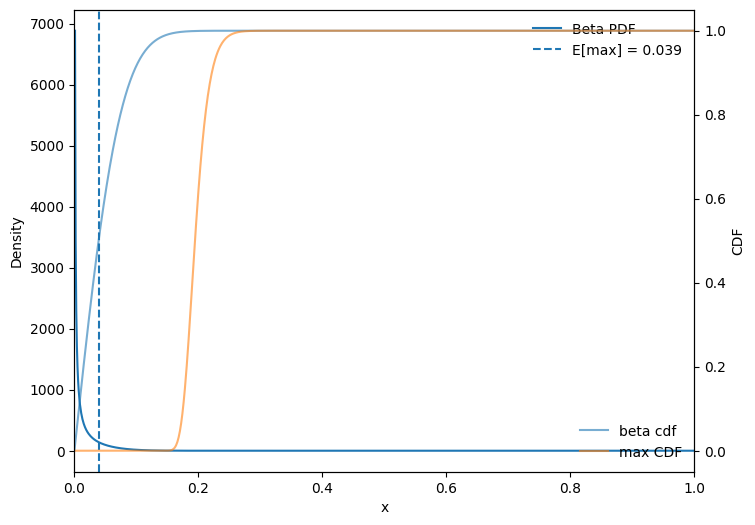

In [52]:
## Load dataset and extract samples and dimensions
n = 1000
d = 300 

x = np.linspace(0, 1, 1000)

## Model the beta distribution for this
a = 0.5
b = (d - 1) / 2

rv = beta(a, b)
pdf = rv.pdf(x**2)

## Get the CDF (maybe use incomplete beta function)
cdf = betainc(a, b, x**2)

## Use for the ordered statistics/maximum the CDF to the power of n 
max_cdf = cdf**n

## Calculate the expected value
expected_max = trapezoid(1 - max_cdf, x**2)
print(f"Expected maximum = {expected_max:.6f}")

## Plot PDF, CDF, CDF to the power and mark expected value. 
fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()
ax1.plot(x, pdf, label='Beta PDF')
ax2.plot(x, cdf, alpha=0.6, label='beta cdf')
ax2.plot(x, max_cdf,  alpha=0.6, label='max CDF')
ax1.axvline(expected_max, linestyle='--', label=f'E[max] = {expected_max:.3f}')
ax1.set_xlabel('x')
ax1.set_ylabel('Density')
ax2.set_ylabel('CDF')
ax1.set_xlim([0, 1])
ax1.legend(loc='best', frameon=False)
ax2.legend(loc='best', frameon=False)
plt.show()


Expected maximum = 0.037620
Expected maximum = 0.074992
Expected maximum = 0.113660


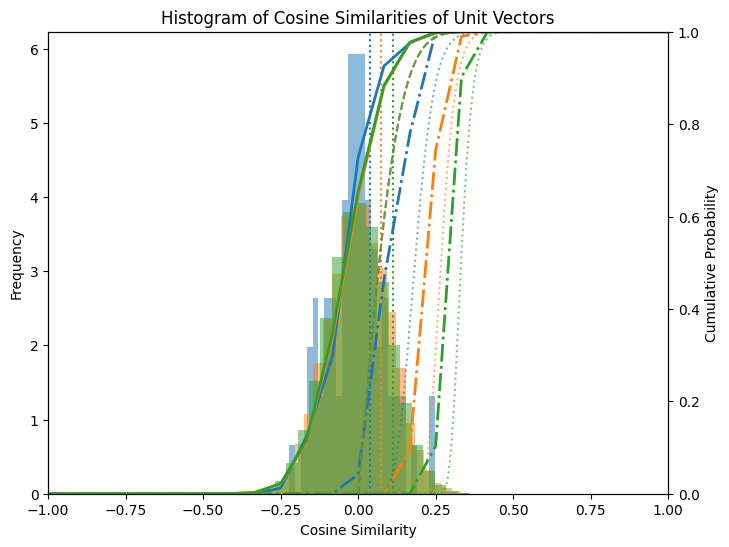

In [54]:
samples = [10, 100, 1000]
d = 100
colors = ['tab:blue', 'tab:orange', 'tab:green']
fig, ax1 = plt.subplots(figsize=(8, 6))
ax2 = ax1.twinx()

for color, n in zip(colors, samples):
    cosine_similarities = []
    for re in range(n): 
        random_points = [random_point_on_unit_sphere(d) for _ in range(n)]

        first_item = random_points[re]
        for j in range(1, len(random_points)):
            if j == re:
                continue
            dot_product = np.dot(first_item, random_points[j])
            cosine_similarities.append(dot_product)
 
    r = cumfreq(cosine_similarities, numbins=25, defaultreallimits=(-1, 1))
    x = r.lowerlimit + np.linspace(0, r.binsize * r.cumcount.size, r.cumcount.size)
    cdf = r.cumcount / r.cumcount[-1]
    c = cdf ** n          # added this later after the velocity meeting

    ax1.hist(cosine_similarities, bins=25, label=f"n = {n}", alpha=0.5, density=True, color=color)
    ax2.plot(x, cdf, label=f"CDF n = {n}", lw=2, linestyle='-', color=color)
    ax2.plot(x, c, label=fr"$F(x)^{{{n}}}$", lw=2, linestyle='dashdot', color=color) # also added this later as the plotting of F(x)^n

    x, pdf, cdf, max_cdf, expected_max = get_theoretical_distribution(n, d)
    #ax1.plot(x, pdf,color=color,  label='Beta PDF')
    ax2.plot(x, cdf, color=color, linestyle= "dashed", alpha=0.6, label='beta cdf')
    ax2.plot(x, max_cdf, color=color, linestyle='dotted', alpha=0.6, label='max CDF')
    ax1.axvline(expected_max, color=color, linestyle='dotted', label=f'E[max] = {expected_max:.3f}')

plt.title("Histogram of Cosine Similarities of Unit Vectors")
ax1.set_xlabel("Cosine Similarity")
ax1.set_ylabel("Frequency")
ax2.set_ylabel("Cumulative Probability")
plt.xlim(-1, 1)
ax2.set_ylim(0, 1)
#plt.legend()
plt.show()